## Project analysing government tendered contracts between 2015 and 2026 tendered by the Ministry of Defence.
The purpose is to analyse a number of government tendered contracts available publically from https://www.contractsfinder.service.gov.uk/ relating to the MOD. I aim to identify trends in spending around key inflection points, notable comparing pre and post full scale invasion of Ukraine in Feb 2022.

Data accounts for contracts published as awarded between 01/01/2015 and 24/09/2026

This markdown will contain the scripts used to intake, clean, and analyse data, alongside produce figures and visualisation.


## Setup and Imports

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
import os
from pathlib import Path
import re


csv_filenames = []
for dirname, _, filenames in os.walk("./contract_data"):
    for filename in filenames:
        csv_filenames.append(os.path.join(dirname, filename))
    
print(csv_filenames)

pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

['./contract_data/notices(4).csv', './contract_data/notices(2).csv', './contract_data/notices.csv', './contract_data/notices(9).csv', './contract_data/notices(7).csv', './contract_data/notices(12).csv', './contract_data/notices(8).csv', './contract_data/notices(10).csv', './contract_data/notices(11).csv', './contract_data/notices(5).csv', './contract_data/notices(15).csv', './contract_data/notices(14).csv', './contract_data/notices(6).csv', './contract_data/notices(3).csv', './contract_data/notices(13).csv', './contract_data/notices(1).csv']


## Data Cleaning

In [2]:
chunks = []
row_counts = {}

for path in csv_filenames:
    chunk = pd.read_csv(path, header=0)          
    chunk["source_file"] = Path(path).name        
    row_counts[Path(path).name] = len(chunk)
    chunks.append(chunk)
# parses each file as csv with header, concats them into filestream, creates dataframe at the end
combined = pd.concat(chunks, ignore_index=True)

# --- sanity checks ---
print(combined.shape)
print(pd.Series(row_counts))                       # rows contributed per file
print("duplicate notice IDs:", combined.duplicated(subset="Notice Identifier").sum())
print("column sets consistent:", len({tuple(c.columns) for c in chunks}) == 1)
print((combined.iloc[:, 0] == combined.columns[0]).sum())  # should be 0

combined.drop_duplicates(subset="Notice Identifier", inplace=True)  # remove duplicates
print("duplicate notice IDs after deduplication:", combined.duplicated(subset="Notice Identifier").sum())

print(combined.shape)

(10223, 44)
notices(4).csv     793
notices(2).csv     521
notices.csv        610
notices(9).csv     654
notices(7).csv     758
notices(12).csv    555
notices(8).csv     474
notices(10).csv    709
notices(11).csv    815
notices(5).csv     802
notices(15).csv    416
notices(14).csv    892
notices(6).csv     421
notices(3).csv     579
notices(13).csv    543
notices(1).csv     681
dtype: int64
duplicate notice IDs: 120
column sets consistent: True
0
duplicate notice IDs after deduplication: 0
(10103, 44)


Some duplicate values because I had slightly overlapping data periods. Shape of each file and entry consistent, number of entries after deduplication matches the number of entries retrieved in a search over the same data range on the original website. 

Supplier column contains many different values, plus multiple suppliers sometimes. For the main df we will just extract the supplier names, number of suppliers. Will create a different df focussing on just supplier info like addresses, CH refs, SME or VCE to reduce redundancy and empty columns.

There are a number of fields containing personal information, as well as unnecessary fields like attachments, redundant supplier info. These will be dropped.


In [3]:
# Dealing with supplier information

multi_supplier = combined["Supplier [Name|Address|Ref type|Ref Number|Is SME|Is VCSE]"].str.count(r"\]\[") > 0
print("rows with multiple suppliers:", multi_supplier.sum())

combined_clean = combined

def parse_supplier_names(raw):
    if pd.isna(raw):
        return []
    groups = re.findall(r"\[(.*?)\]", raw, flags=re.DOTALL)
    return [g.split("|")[0].strip() for g in groups]

combined_clean["supplier_names"] = combined["Supplier [Name|Address|Ref type|Ref Number|Is SME|Is VCSE]"].apply(parse_supplier_names)
combined_clean["n_suppliers"] = combined["supplier_names"].apply(len)
combined_clean["supplier_names_joined"] = combined["supplier_names"].apply(lambda lst: "; ".join(lst))


rows with multiple suppliers: 315


In [4]:
# Removing personal information from suppliers and dropping unnecessary columns
personal_info_cols = combined_clean.filter(regex=r"(?i)contact|phone|email|tel|post").columns
print(personal_info_cols.tolist())
combined_clean.drop(columns=personal_info_cols, inplace=True)
combined_clean.drop("Supplier [Name|Address|Ref type|Ref Number|Is SME|Is VCSE]", axis=1, inplace=True)
combined_clean.drop("Attachments", axis=1, inplace=True)
combined_clean["awarded_date"] = pd.to_datetime(combined_clean["Awarded Date"], dayfirst=True, errors="coerce")

combined_clean.head()


['Postcode', 'Contact Name', 'Contact Email', 'Contact Address 1', 'Contact Address 2', 'Contact Town', 'Contact Postcode', 'Contact Country', 'Contact Telephone', 'Contact Website', "Supplier's contact name"]


,Notice Identifier,Notice Type,Organisation Name,Status,Published Date,Title,Description,Nationwide,Region,Cpv Codes,Links,Additional Text,Start Date,End Date,Closing Date,Is sub-contract,Parent Reference,Suitable for SME,Suitable for VCO,Supply Chain,OJEU Contract Type,Value Low,Value High,Awarded Date,Awarded Value,Contract start date,Contract end date,OJEU Procedure Type,Accelerated Justification,Closing Time,source_file,supplier_names,n_suppliers,supplier_names_joined,awarded_date
0,FLEET/ 00748,Contract,Ministry Of Defence,Awarded,2019-01-02T11:59:24Z,Provision of 4G Services to Support Operationa...,Provision of 4G Services to Support Operationa...,NaN,South East,32584000,NaN,NaN,12/12/2018,11/12/2020,06/12/2018,NO,NaN,No,No,No,Works,1096320.00,NaN,10/12/2018,1096320.00,12/12/2018,11/12/2020,CallOffFromFrameworkAgreement,NaN,NaN,notices(4).csv,[NSSLGlobal Ltd],1,NSSLGlobal Ltd,2018-12-10
1,CCIH18A65.,Contract,Army HQ (Andover) : Ministry of Defence,Awarded,2019-01-03T10:14:25Z,Provision of Warfare Laptops,Warfare Laptops,NaN,Any region,30200000,NaN,NaN,14/12/2018,18/12/2018,13/12/2018,NO,NaN,No,No,No,Products,0.00,12510.0,13/12/2018,12510.00,14/12/2018,18/12/2018,CallOffFromFrameworkAgreement,NaN,NaN,notices(4).csv,[CENTERPRISE INTERNATIONAL LIMITED],1,CENTERPRISE INTERNATIONAL LIMITED,2018-12-13
2,SSP/00240 - Development of Ammo,Contract,Ministry Of Defence,Awarded,2019-01-03T14:34:23Z,SSP/00240 - Development of Ammo,Contract for the development of Ammunition.,NaN,South West,35330000,NaN,NaN,17/12/2018,17/07/2019,16/12/2018,NO,NaN,Yes,No,No,Services,39000.00,NaN,16/12/2018,39000.00,17/12/2018,17/07/2019,SingleTenderActionNonOJEU,NaN,NaN,notices(4).csv,[Cranfield University],1,Cranfield University,2018-12-16
3,DFFS/5072/0056,Contract,Ministry Of Defence,Awarded,2019-01-04T14:22:15Z,Bulk Fuels Framework Agreement - DFFS/5072 - I...,CALL OFF FROM FRAMEWORK AGREEMENT - Bulk Fuels...,NaN,Any region,09100000,NaN,NaN,01/02/2019,30/03/2019,04/01/2019,YES,DFFS/5072/0056,No,No,No,Products,8030000.00,NaN,04/01/2019,8030000.00,01/02/2019,30/03/2019,CallOffFromFrameworkAgreement,NaN,NaN,notices(4).csv,[MOTOR OIL (HELLAS) CORINTH REFINERIES S.A.],1,MOTOR OIL (HELLAS) CORINTH REFINERIES S.A.,2019-01-04
4,CCIH18A80.,Contract,Joint Forces Command - Headquarters (Northwood...,Awarded,2019-01-04T14:52:43Z,"Deployable Workstations, Software, Accessories...","Deployable Workstations, Software, Accessories...",NaN,Any region,30000000,NaN,NaN,21/12/2019,21/12/2020,04/01/2019,NO,NaN,Yes,No,No,Products,246792.02,NaN,20/12/2018,246792.02,21/12/2018,21/12/2018,CallOffFromFrameworkAgreement,NaN,NaN,notices(4).csv,[SOFTWARE BOX LIMITED],1,SOFTWARE BOX LIMITED,2018-12-20


In [5]:
# Checking new datetime column 
print(combined_clean["awarded_date"].dtype)                    # should be datetime64
print(combined_clean["awarded_date"].isna().sum())              # how many failed to parse
print(combined_clean.loc[combined_clean["awarded_date"].isna(), "Awarded Date"].unique()) 
print(combined_clean["awarded_date"].min(), combined_clean["awarded_date"].max()) 

datetime64[ns]
2
[nan]
2003-02-16 00:00:00 2026-12-18 00:00:00


In [6]:
# Identifying weird dates outside the expected range
weird = combined_clean[(combined_clean["awarded_date"].dt.year < 2014) | (combined_clean["awarded_date"].dt.year > 2026)]
print(weird[["Notice Identifier", "Title", "awarded_date"]].to_string())

                       Notice Identifier                                                                                                                                          Title awarded_date
924                          BIP52786504                                                                 Support, Repair and Calibration of RAF General Purpose Automatic Test Systems.   2008-03-29
994                          BIP53788620                                                                              Supply and In Service Support for Medium Aircraft Towing Tractors   2008-01-18
1066                         BIP54933687                                                                                    Repair of AMOS MK2 Consoles and Type 417F Oxygen Regulators   2012-03-31
1180                         BIP57151196                                                             Technical Support Services for Aircrew Clothing, Liferafts & Associated Equipments   2011-04-01
1181           

There are a few strange values when organising data based on the awarded date. This is a human entered value so most likely just input error when creating the record. Published date might be more reliable as it's likely a system generated value rather than human input. Here I will compare the publishing and award dates and create a flag for rows with large time lag between award and publishing dates.

In [7]:
# how many pre-2015 dates exist in each column?
print("awarded_date pre-2015:", (combined_clean["awarded_date"].dt.year < 2015).sum())

pub = pd.to_datetime(combined_clean["Published Date"], utc=True).dt.tz_localize(None)
print("published_date pre-2015:", (pub.dt.year < 2015).sum())
print("published_date range:", pub.min(), pub.max())

awarded_date pre-2015: 31
published_date pre-2015: 0
published_date range: 2015-03-05 12:50:22 2026-09-24 10:34:34


In [8]:
# calculating lag between published date and awarded date
pub = pd.to_datetime(combined_clean["Published Date"], utc=True).dt.tz_localize(None)

combined_clean["lag_days"] = (combined_clean["awarded_date"] - pub).dt.days
combined_clean["award_year"] = combined_clean["awarded_date"].dt.year
print(combined_clean.groupby("award_year")["lag_days"].median())
print(combined_clean.groupby("award_year")["lag_days"].mean())
print(combined_clean.groupby("award_year")["lag_days"].std())

award_year
2003.0   -6100.5
2004.0   -4698.0
2005.0   -4166.0
2006.0   -4244.0
2008.0   -3346.0
2011.0   -2358.0
2012.0   -2029.0
2013.0   -1591.0
2014.0    -229.0
2015.0     -23.0
2016.0     -15.0
2017.0     -20.0
2018.0     -17.0
2019.0     -21.0
2020.0     -25.0
2021.0     -20.0
2022.0     -28.0
2023.0     -22.0
2024.0     -20.0
2025.0     -22.0
2026.0     -20.0
Name: lag_days, dtype: float64
award_year
2003.0   -6100.500000
2004.0   -4764.333333
2005.0   -4166.000000
2006.0   -4244.000000
2008.0   -3346.000000
2011.0   -2406.000000
2012.0   -2029.000000
2013.0   -1591.000000
2014.0    -288.866667
2015.0     -54.635211
2016.0     -27.646774
2017.0     -49.104587
2018.0     -50.084063
2019.0     -48.170940
2020.0    -108.470524
2021.0     -49.748357
2022.0     -68.008607
2023.0     -42.198777
2024.0     -37.547507
2025.0     -40.560948
2026.0     -20.871972
Name: lag_days, dtype: float64
award_year
2003.0    1822.214175
2004.0     185.613398
2005.0            NaN
2006.0            Na

There are some instances where the published date and awarded date differ greatly, with many where the awarded date is in years preceding the range of the data available (which started in 2015). Some of these are likely input errors. For awarded dates between 2015 and 2026, the lag days were relatively stable, with stdev never more than 210 days, means and medians within range of 1-2 months. Firstly, the negative means and median values imply that a contract is awarded first, then details are published later. Second, for the overwhelming majority of entries, award and publication date are relatively similar. 
I will flag entries where the award dates differ massively from the publication dates, and exclude these from any analysis where award date is used.

In [9]:
# flag anything with an implausible lag, regardless of what year it landed in
lag_threshold_days = 365 # a year seems like a reasonable threshold for an acceptable lag between publication and award date 
combined_clean["lag_flag"] = combined_clean["lag_days"].abs() > lag_threshold_days

print(combined_clean["lag_flag"].sum())
print(combined_clean.loc[combined_clean["lag_flag"], ["Notice Identifier", "Title", "awarded_date", "Published Date", "lag_days"]])

240
                                       Notice Identifier  \
15                                            CCIH16A22.   
25                                           JFC6c/00052   
108                                           CCOE17A08.   
288                                           HELSS/0066   
319                                          BIP68033916   
320                                          BIP75119708   
334                                          BIP74840605   
510                                           CCSO19A53.   
654                                          BIP60943860   
658                                          BIP68113054   
659                                          BIP80406916   
660                                          BIP80415679   
675                                          BIP80684775   
924                                          BIP52786504   
935                                          BIP36422947   
985                                 

In [10]:
print(combined_clean["lag_days"].isna().sum())
print(combined_clean[combined_clean["lag_days"].isna()]["lag_flag"].unique())  # confirm these show as False, not True

combined_clean[~combined_clean["lag_flag"]].groupby("award_year")["lag_days"].agg(["mean", "median", "std"])

2
[False]


,mean,median,std
award_year,,,
2014.0,-210.538462,-229.0,76.830566
2015.0,-42.804286,-23.0,66.149505
2016.0,-21.127243,-14.0,49.206449
2017.0,-40.588454,-19.0,60.066444
2018.0,-31.293694,-16.0,47.000751
2019.0,-35.731677,-21.0,43.231530
2020.0,-51.465144,-22.0,75.851341
2021.0,-39.645315,-19.5,56.289353
2022.0,-56.369268,-27.0,77.086654


In [11]:
combined_clean.to_csv("combined_contract_data.csv", index=False)


In [12]:
combined_clean.shape

(10103, 38)

## Exploratory Analysis

The first thing to look at is number of contracts over time. We will do this as a bar chart looking split across months and years.

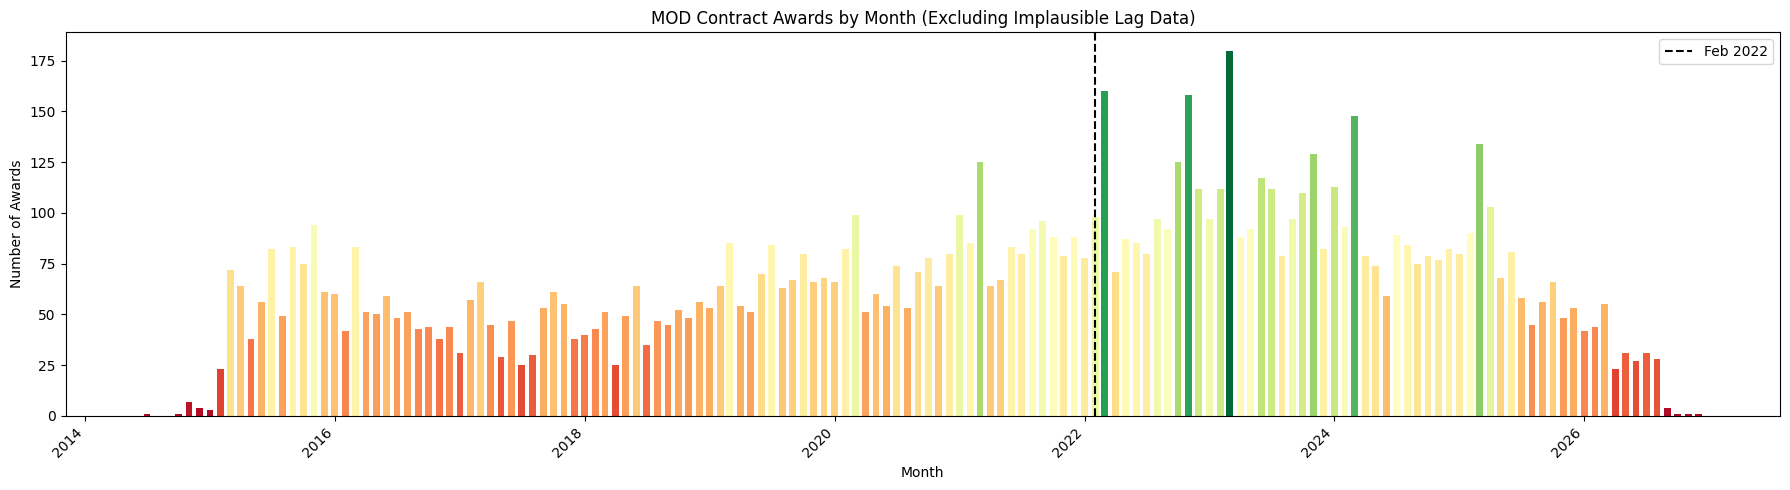

In [13]:

# Colour values based on y value of the bar, using a seaborn palette
def colors_from_values(values, palette_name):
    # normalize the values to range [0, 1]
    normalized = (values - min(values)) / (max(values) - min(values))
    # convert to indices
    indices = np.round(normalized * (len(values) - 1)).astype(np.int32)
    # use the indices to get the colors
    palette = sns.color_palette(palette_name, len(values))
    return np.array(palette).take(indices, axis=0)


clean_data = combined_clean[~combined_clean["lag_flag"]].copy()

# collapse to year-month so each period appears once, in chronological order
clean_data["year_month"] = clean_data["awarded_date"].dt.to_period("M").dt.to_timestamp()

monthly = clean_data.groupby("year_month").size().reset_index(name="n_notices")
full_range = pd.date_range(clean_data["year_month"].min(), clean_data["year_month"].max(), freq="MS") # fills in missing months with 0s
monthly = monthly.set_index("year_month").reindex(full_range, fill_value=0).rename_axis("year_month").reset_index()


colors = colors_from_values(monthly["n_notices"], "RdYlGn")

plt.figure(figsize=(18, 5))
plt.bar(monthly["year_month"], monthly["n_notices"], color=colors, width=20)

ax = plt.gca()
#for i, label in enumerate(ax.get_xticklabels()):
#    label.set_visible(i % 1 == 0)
plt.xticks(rotation=45, ha="right")

event_idx = monthly[monthly["year_month"] == "2022-02-01"].index
if len(event_idx):
    plt.axvline(monthly["year_month"].iloc[event_idx[0]], color="black", linestyle="--", label="Feb 2022")
    plt.legend()

plt.title("MOD Contract Awards by Month (Excluding Implausible Lag Data)")
plt.xlabel("Month")
plt.ylabel("Number of Awards")
plt.tight_layout()
plt.show()

Initial impressions seem to suggest that the number of tenders increases noticeably after February 2022. But this data doesn't distinguish between types of contracts so it's not yet known if these relate to thing that might have been motivated by the ukraine war. However it's possible that defence procurement and spending increased generally across all kinds of contracts in response just based on an increased need for overall readiness and upkeep in the face of a modern conflict within europe.

Next I will group the contracts by their CPV code, which is a kind of standardised identifier used to classify contracts based on the kinds of goods, services and work they require. 

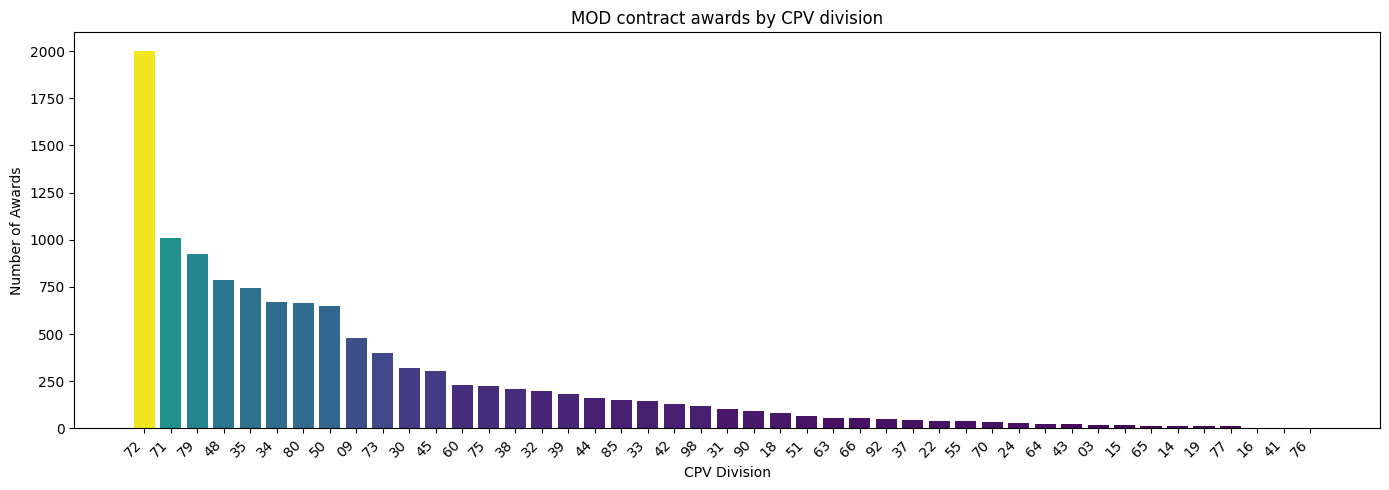

In [14]:

# Colour values based on y value of the bar, using a seaborn palette
def colors_from_values(values, palette_name):
    # normalize the values to range [0, 1]
    normalized = (values - min(values)) / (max(values) - min(values))
    # convert to indices
    indices = np.round(normalized * (len(values) - 1)).astype(np.int32)
    # use the indices to get the colors
    palette = sns.color_palette(palette_name, len(values))
    return np.array(palette).take(indices, axis=0)



clean_data = combined_clean.copy()

# split the multi-code string into a list, handle missing values
clean_data["cpv_list"] = clean_data["Cpv Codes"].fillna("").str.split()

# explode so each row-code pair gets counted separately
# (a contract with 2 codes contributes to both categories)
exploded = clean_data.explode("cpv_list")
exploded = exploded[exploded["cpv_list"] != ""]   # drop rows with no code at all

# bucket to CPV division (first 2 digits) rather than full 8-digit code
exploded["cpv_division"] = exploded["cpv_list"].str[:2]

division_counts = exploded.groupby("cpv_division").size().reset_index(name="n_by_division")
division_counts = division_counts.sort_values("n_by_division", ascending=False)

# print(division_counts)   # eyeball this before plotting — how many distinct divisions are there?

top_n = 50
top = division_counts.head(top_n)
other_total = division_counts["n_by_division"].iloc[top_n:].sum()
division_counts_plot = pd.concat([top, pd.DataFrame([{"cpv_division": "Other", "n_by_division": other_total}])])

colors = colors_from_values(division_counts["n_by_division"].values, "viridis") 

plt.figure(figsize=(14, 5))
plt.bar(division_counts["cpv_division"], division_counts["n_by_division"], color=colors, width=0.8)
plt.xticks(rotation=45, ha="right")
plt.title("MOD contract awards by CPV division")
plt.xlabel("CPV Division")
plt.ylabel("Number of Awards")
plt.tight_layout()
plt.show()

I suppose it isn't too surprising that the most common higher order division for contracts is 720000000. This is "IT services". Next is 710000000, which is architectural, construction, engineering services. Then 790000000 is Business services like law, marketing, recruiting, security. These are all contracts that likely relate to general maintenance and ongoing support for various parts of the MoD. 
The code starting 48 is for software, and the first sort of procurement related code is the code starting 35 which refers to defence equipment. 

                                  supplier_names  n_awards
4583                        SOFTWARE BOX LIMITED        76
1073           CENTERPRISE INTERNATIONAL LIMITED        70
1681                                Deloitte LLP        56
3351  MOTOR OIL (HELLAS) CORINTH REFINERIES S.A.        52
2916                                    KPMG LLP        50
714                                BOXXE LIMITED        48
126                     AKHTER COMPUTERS LIMITED        47
3890              PA CONSULTING SERVICES LIMITED        38
906                                Boxxe Limited        37
616            BAE Systems Surface Ships Limited        35
1276                            Carbon60 Limited        34
1033            CAPITA BUSINESS SERVICES LIMITED        31
1312           Centerprise International Limited        30
4161                             QinetiQ Limited        29
1313               Centerprise International Ltd        27
83                     ACTICA CONSULTING LIMITED        

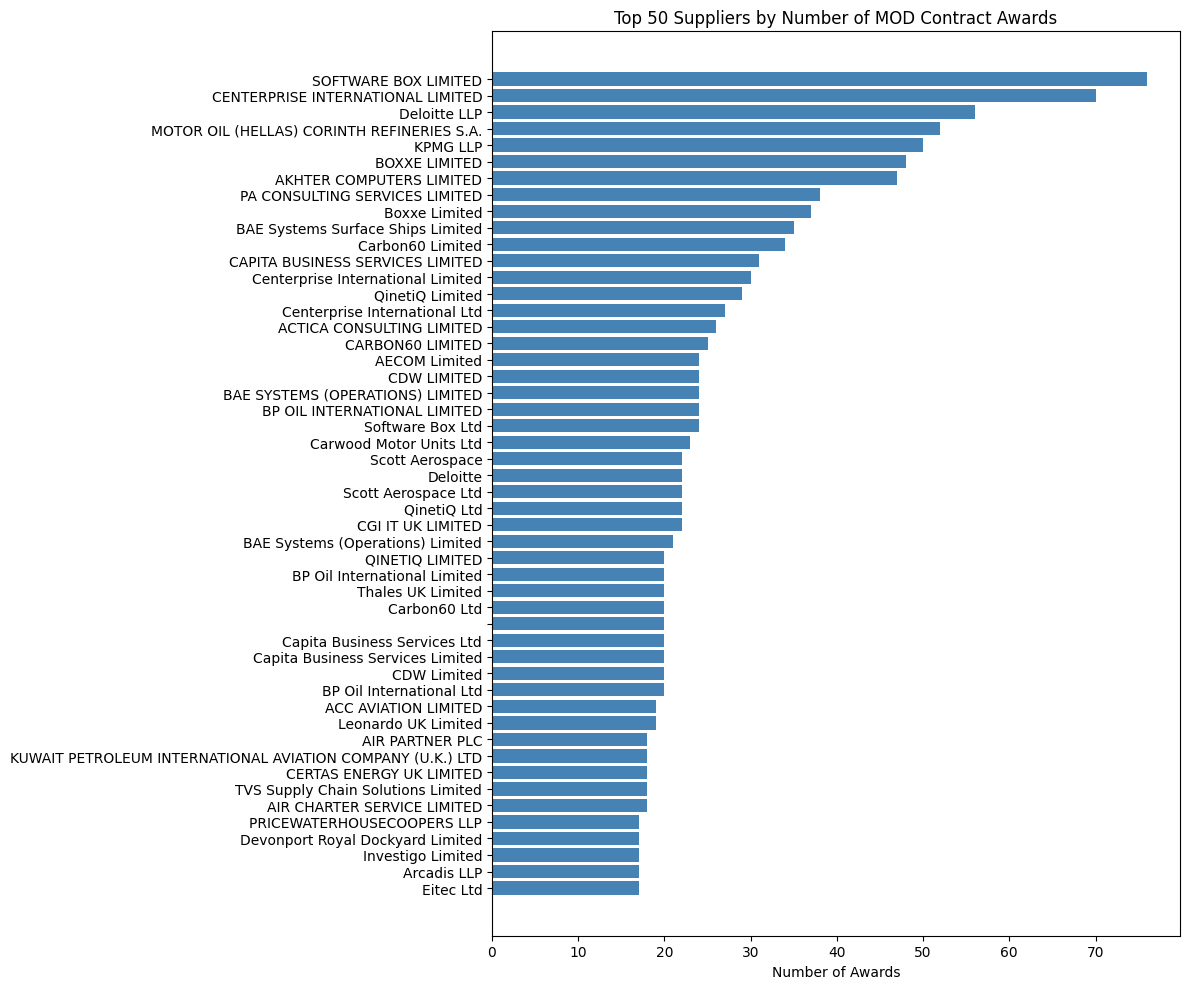

In [15]:

supplier_counts_data = combined_clean[~combined_clean["lag_flag"]].copy()

suppliers_exploded = supplier_counts_data.explode("supplier_names")
suppliers_exploded = suppliers_exploded[suppliers_exploded["supplier_names"].notna()]

supplier_counts = (
    suppliers_exploded.groupby("supplier_names")
    .size()
    .reset_index(name="n_awards")
    .sort_values("n_awards", ascending=False)
)

print(supplier_counts.head(20))
print("n unique suppliers:", supplier_counts.shape[0])

# look for near-duplicate names via a simple normalisation pass
normalized = suppliers_exploded["supplier_names"].str.strip().str.upper().str.replace(r"[.,]", "", regex=True)
print(normalized.nunique(), "vs raw:", suppliers_exploded["supplier_names"].nunique())

top_n = 50
top_suppliers = supplier_counts.head(top_n)

plt.figure(figsize=(12, 10))
plt.barh(top_suppliers["supplier_names"], top_suppliers["n_awards"], color="steelblue")
plt.gca().invert_yaxis()   # largest at top
plt.xlabel("Number of Awards")
plt.title(f"Top {top_n} Suppliers by Number of MOD Contract Awards")
plt.tight_layout()
plt.show()


Next we will break down the 350000000 code into its sub-elements to view the number of contracts within each type

In [16]:
# --- CPV 35 sub-groups ---
CPV35_GROUPS = {
    "351": "Emergency & security equipment",
    "352": "Police equipment",
    "353": "Weapons & ammunition",
    "354": "Military vehicles",
    "355": "Warships",
    "356": "Military aircraft, missiles & spacecraft",
    "357": "Military electronic systems",
    "358": "Individual & support equipment",
}

base = combined_clean[~combined_clean["lag_flag"]].copy()
base["cpv_list"] = base["Cpv Codes"].fillna("").astype(str).str.split()

exp = base.explode("cpv_list")
exp = exp[exp["cpv_list"].notna() & (exp["cpv_list"] != "")]
exp["cpv_division"] = exp["cpv_list"].str[:2]

defence = exp[exp["cpv_division"] == "35"].copy()
defence["cpv35_group"] = defence["cpv_list"].str[:3].map(CPV35_GROUPS)

# a contract with two codes in the same group shouldn't count twice
defence = defence.drop_duplicates(subset=["Notice Identifier", "cpv35_group"])

print(defence["cpv35_group"].value_counts(dropna=False))

cpv35_group
Warships                                    135
Military vehicles                           127
Weapons & ammunition                        110
Military electronic systems                  94
Emergency & security equipment               82
Military aircraft, missiles & spacecraft     76
NaN                                          35
Individual & support equipment               30
Police equipment                             10
Name: count, dtype: int64


Warships and vehicles were the most common types of contracts. Not hugely surprising as these require massive effort to build and maintain.

Next we will try to group contracts based on various keywords found in the title and description. This will cover the full set of contracts not just those starting with 350... code. This includes a step to validate the extracted entries for false positives. False negatives have no been evaluated here but sampling a selection of entries not included in these themes for any potentially matching or relevant phrases would give an indication of the rate at which relevant entries are missed by this methodology.

In [25]:
# --- Keyword themes (multi-label) across ALL contracts ---
THEMES = {
    "uncrewed_systems": r"\b(?:uav|uas|drones?|unmanned|uncrewed|rpas|loitering)\b",
    "counter_uas":      r"\b(?:c-uas|counter[- ]uas|counter[- ]drone)\b",
    "munitions":        r"\b(?:ammunition|munitions?|missiles?|warheads?|ordnance|explosives?|artillery)\b",
    "air_defence":      r"\b(?:air defen[cs]e|gbad|sky sabre|camm)\b",
    "c4isr_comms":      r"\b(?:c4isr|isr|radar|sensors?|comms|communications|radio|satcom|crypto)\b",
    "cyber_it":         r"\b(?:cyber|software|licen[cs]es?|cloud|it services|network)\b",
    "support_repair":   r"\b(?:repair|overhaul|spares|maintenance|in[- ]service support|pds)\b",
    "training":         r"\b(?:training|simulat\w+|trainer)\b",
}

text = (base["Title"].fillna("") + " " + base["Description"].fillna("")).str.lower()

for theme, pattern in THEMES.items():
    base[f"{theme}_hits"] = text.str.findall(pattern)       # list of matched words per row
    base[theme] = base[f"{theme}_hits"].str.len() > 0        # True if any match

theme_cols = list(THEMES)
base["n_themes"] = base[theme_cols].sum(axis=1)

# --- Summary ---
print(base[theme_cols].sum().sort_values(ascending=False))
print("unclassified share:", round((base["n_themes"] == 0).mean(), 3))

# --- Which keywords drive each theme (across all tagged contracts) ---
for theme in theme_cols:
    print(f"\n{theme}:")
    print(base[f"{theme}_hits"].explode().value_counts().head(10))


def clean(s):
    """Collapse newlines, tabs and repeated spaces into single spaces."""
    return re.sub(r"\s+", " ", str(s)).strip()

def keyword_context(text, pattern, width=60):
    """Return the text around each match, e.g. '...supply of unmanned aerial...'"""
    snippets = []
    for m in re.finditer(pattern, text):
        start, end = max(m.start() - width, 0), min(m.end() + width, len(text))
        snippets.append("..." + clean(text[start:end]) + "...")
    return " | ".join(snippets)

def check_theme(theme, n=15, seed=1):
    tagged = base[base[theme]]
    sample = tagged.sample(min(n, len(tagged)), random_state=seed).copy()
    sample["Title"] = sample["Title"].apply(clean)
    sample["context"] = text.loc[sample.index].apply(lambda t: keyword_context(t, THEMES[theme]))
    return sample[["Notice Identifier", "Title", f"{theme}_hits", "context"]]
check_theme("uncrewed_systems")

cyber_it            1433
support_repair      1358
training            1002
c4isr_comms          319
munitions            159
uncrewed_systems      66
air_defence           17
counter_uas            4
dtype: int64
unclassified share: 0.634

uncrewed_systems:
uncrewed_systems_hits
uas          34
unmanned     31
uncrewed     29
drone        10
drones        3
rpas          3
uav           2
loitering     2
Name: count, dtype: int64

counter_uas:
counter_uas_hits
c-uas    9
Name: count, dtype: int64

munitions:
munitions_hits
artillery     64
explosive     63
ordnance      60
ammunition    59
munitions     50
missile       24
explosives     9
munition       4
missiles       2
Name: count, dtype: int64

air_defence:
air_defence_hits
air defence    24
gbad            8
sky sabre       2
Name: count, dtype: int64

c4isr_comms:
c4isr_comms_hits
communications    191
radio              99
radar              92
sensors            69
sensor             43
comms              28
satcom            

,Notice Identifier,Title,uncrewed_systems_hits,context
6049,BIP84030374,Minerva - Integration and Facilitation,[unmanned],...facilitation activities on an authority-own...
8576,BIP60862352,Procurement of a Zeus Situation Awareness Tool...,[unmanned],...ol license to aid in the development of the...
6210,700495368,The Provision of a Temporary Programme Manager...,[unmanned],...of a temporary programme manager for the fl...
469,700006954,Provision of Technical Support for Small Remot...,"[rpas, rpas]",...chnical support for small remotely piloted ...
5757,tender_401959/1288815,709392450 - Uncrewed Surface/Sub-Surface Vesse...,"[uncrewed, uncrewed]",...709392450 - uncrewed surface/sub-surface ve...
8199,701549389,Logistic Drone Swarm Experimentation,[drone],...logistic drone swarm experimentation this c...
4520,tender_340612/1179607,CAN - 705996451 USSV Demonstrator,[uncrewed],...can - 705996451 ussv demonstrator 705996451...
4623,tender_356775/1186008,704364450 Westlant 22 (HLC1),[uas],...stlant 22 (hlc1) services related to accele...
7846,715617453,Maritime Big Play,[uncrewed],...automation of asw processing to increase th...
5767,tender_400724/1289332,Mission Capable Autonomy,[uncrewed],"...ll as intelligence, surveillance and reconn..."


In [29]:
for theme in theme_cols:
    path = f"verification_{theme}.csv"
    if os.path.exists(path):
        print(f"skipping {path} (already exists)")
        continue
    s = check_theme(theme, n=30)
    s["correct"] = ""
    s.to_csv(path, index=False, quoting=csv.QUOTE_ALL)

skipping verification_uncrewed_systems.csv (already exists)
skipping verification_counter_uas.csv (already exists)
skipping verification_munitions.csv (already exists)
skipping verification_air_defence.csv (already exists)
skipping verification_c4isr_comms.csv (already exists)
skipping verification_cyber_it.csv (already exists)
skipping verification_support_repair.csv (already exists)
skipping verification_training.csv (already exists)


In [28]:
VERDICTS = {
    "true": True, "correct": True, "yes": True, "y": True, "1": True,
    "false": False, "incorrect": False, "wrong": False, "no": False, "n": False, "0": False,
}

for theme in theme_cols:
    v = pd.read_csv(f"verification_{theme}.csv")
    marks = (
        v["correct"].astype(str).str.strip().str.lower()
        .map(VERDICTS)                     # unrecognised or blank → NaN
    )
    reviewed = marks.notna().sum()
    if reviewed == 0:
        print(f"{theme}: not reviewed yet")
        continue
    print(f"{theme}: {int(marks.sum())}/{reviewed} correct ({marks.mean():.0%}), "
          f"{len(v) - reviewed} unmarked or unrecognised")

uncrewed_systems: not reviewed yet
counter_uas: not reviewed yet
munitions: not reviewed yet
air_defence: 17/17 correct (100%), 0 unmarked or unrecognised
c4isr_comms: not reviewed yet
cyber_it: not reviewed yet
support_repair: not reviewed yet
training: not reviewed yet


Next we will focus in on the uncrewed systems entries. I want to examine the temporal distribution of contracts of this theme from before and after the beginning of the Ukraine war in Feb 2022.

In [33]:
WAR_START = pd.Timestamp("2022-02-24")
theme = "uncrewed_systems"

df = base[base["awarded_date"].notna()].copy()
df["period"] = np.where(df["awarded_date"] < WAR_START, "pre", "post")

months = {
    "pre":  (WAR_START - df["awarded_date"].min()).days / 30.44,
    "post": (df["awarded_date"].max() - WAR_START).days / 30.44,
}

summary = df.groupby("period").agg(
    total_awards=(theme, "size"),
    theme_awards=(theme, "sum"),
)
summary["months"] = summary.index.map(months)
summary["theme_per_month"] = summary["theme_awards"] / summary["months"]
summary["share_of_awards_%"] = summary["theme_awards"] / summary["total_awards"] * 100
summary.loc[["pre", "post"]]


,total_awards,theme_awards,months,theme_per_month,share_of_awards_%
period,,,,,
pre,5265,29,91.392904,0.317311,0.550807
post,4596,37,57.752957,0.640660,0.805048


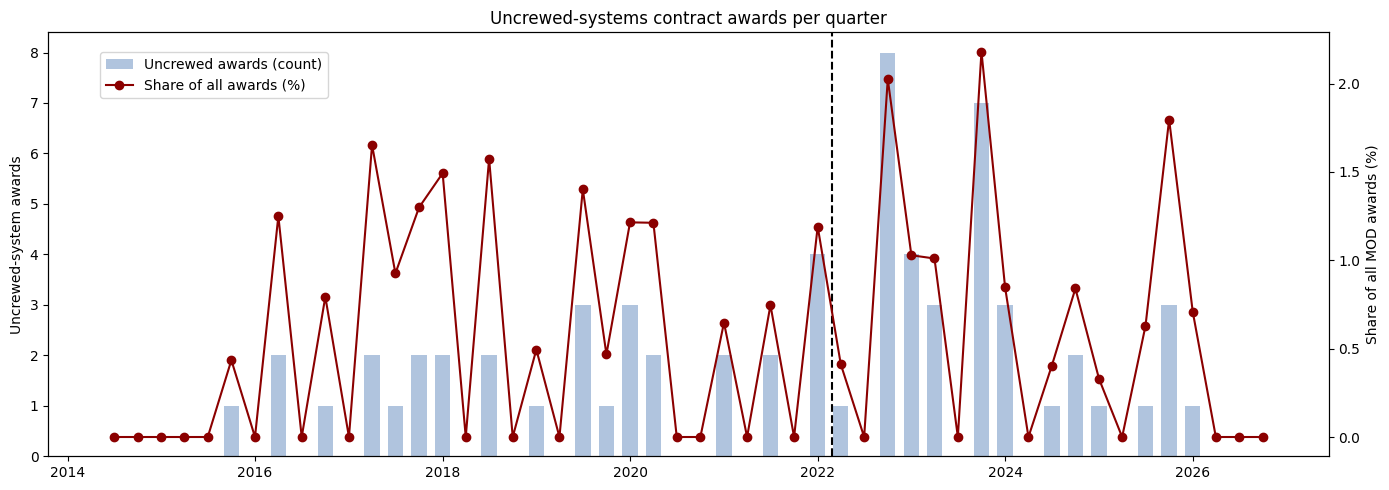

In [34]:
df["quarter"] = df["awarded_date"].dt.to_period("Q").dt.to_timestamp()
quarterly = df.groupby("quarter").agg(total=(theme, "size"), tagged=(theme, "sum"))
quarterly["share_%"] = quarterly["tagged"] / quarterly["total"] * 100

fig, ax1 = plt.subplots(figsize=(14, 5))
ax1.bar(quarterly.index, quarterly["tagged"], width=60, color="lightsteelblue", label="Uncrewed awards (count)")
ax2 = ax1.twinx()
ax2.plot(quarterly.index, quarterly["share_%"], color="darkred", marker="o", label="Share of all awards (%)")
ax1.axvline(WAR_START, color="black", linestyle="--")
ax1.set_ylabel("Uncrewed-system awards")
ax2.set_ylabel("Share of all MOD awards (%)")
ax1.set_title("Uncrewed-systems contract awards per quarter")
fig.legend(loc="upper left", bbox_to_anchor=(0.07, 0.9))
plt.tight_layout()
plt.show()

The two above cells clearly show an increase in contract awards related to uncrewed systems post 2022 Ukraine invasion. This increase is both in absolute value, as well as the share of overall contracts which related to uncrewed systems. The number of awards per month increased from around 0.3 to around 0.6, showing more than double the average number of contracts per month being related to uncrewed systems post ukraine invasion. Additionally, the share of contracts related to uncrewed sysems as a % of the total number of contracts for each period rose from 0.54% to over 0.8% after the invasion. As we might expect, the war in ukraine kick started both a resurgance in the number of procurement contracts, as well as the importance of uncrewed systems contracts in relation to overall procurement. 

In [35]:
rng = np.random.default_rng(42)
draws = {}
for p in ["pre", "post"]:
    k, n = summary.loc[p, "theme_awards"], summary.loc[p, "total_awards"]
    draws[p] = rng.beta(1 + k, 1 + n - k, size=100_000)   # uniform prior

diff = (draws["post"] - draws["pre"]) * 100
print(f"P(post share > pre share): {(diff > 0).mean():.3f}")
print(f"Difference in share: {np.median(diff):.2f} pp "
      f"(95% interval {np.percentile(diff, 2.5):.2f} to {np.percentile(diff, 97.5):.2f})")

P(post share > pre share): 0.937
Difference in share: 0.26 pp (95% interval -0.07 to 0.60)


In [38]:

vals = df[df[theme]].groupby("period")["Awarded Value"].agg(["count", "sum", "median", "max"])
pd.options.display.float_format = "{:,.0f}".format
vals.loc[["pre", "post"]]

,count,sum,median,max
period,,,,
pre,29,"463,085,799","223,333","415,000,000"
post,37,"309,507,177","400,000","129,350,000"


In [37]:
def norm_name(s):
    s = re.sub(r"[.,]", "", str(s).upper())
    s = re.sub(r"\b(LIMITED|LTD|PLC|LLP)\b", "", s)
    return re.sub(r"\s+", " ", s).strip()

sup = df[df[theme]].explode("supplier_names").dropna(subset=["supplier_names"])
sup["supplier"] = sup["supplier_names"].apply(norm_name)

pre_set = set(sup.loc[sup["period"] == "pre", "supplier"])
post_set = set(sup.loc[sup["period"] == "post", "supplier"])
print(f"pre suppliers: {len(pre_set)}, post suppliers: {len(post_set)}, "
      f"new post-war entrants: {len(post_set - pre_set)}")

sup[sup["period"] == "post"]["supplier"].value_counts().head(15)

pre suppliers: 25, post suppliers: 54, new post-war entrants: 49


supplier
VIKING ARMS                   3
IAN EDGAR (LIVERPOOL)         2
ELBIT SYSTEMS UK              2
MARLBOROUGH COMMUNICATIONS    2
STELLER SYSTEMS               2
COPTRZ                        2
LEONARDO UK                   2
LIVELINK AEROSPACE            2
AETHER AEROSPACE              2
COLENA (T/A HELIGUY)          1
LOCKHEED MARTIN UK            1
SYOS AEROSPACE                1
DONECLE                       1
EVOLVE DYNAMICS UK            1
HYBRID DRONES                 1
Name: count, dtype: int64